## 6 | Data Visualization

I use visualizations to communicate the main findings from my SQL analysis, focusing on team performance, scoring efficiency, and individual player contributions.

### 6.1 | Comparing Spain and Argentina's Performance

I compare the teams' attacking and defensive records using goals scored and conceded per match. These metrics provide a consistent basis for comparison because both teams played eight matches.

In [1]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from pathlib import Path

# Connect to the existing World Cup database
db_path = Path.cwd().parent / "Data" / "Prepared" / "world_cup_2026.db"

conn = sqlite3.connect(db_path)

print("Connected to World Cup database!")


Connected to World Cup database!


In [2]:
# Configure folders for exported charts and tables
project_root = Path.cwd().parent

charts_dir = project_root / "Outputs" / "Charts"
tables_dir = project_root / "Outputs" / "Tables"

charts_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

print("Output folders ready!")
print("Charts:", charts_dir)
print("Tables:", tables_dir)

Output folders ready!
Charts: /Users/raulbrand/Desktop/Personal/Project Folder/world-cup-2026-analysis/Outputs/Charts
Tables: /Users/raulbrand/Desktop/Personal/Project Folder/world-cup-2026-analysis/Outputs/Tables


In [3]:
# Verify the database connection and project structure
print("Project root:", project_root)
print("Database path:", db_path)
print("Database exists:", db_path.is_file())

# Confirm the database contains our match data
check_df = pd.read_sql_query(
    "SELECT COUNT(*) AS total_matches FROM matches",
    conn
)

display(check_df)

Project root: /Users/raulbrand/Desktop/Personal/Project Folder/world-cup-2026-analysis
Database path: /Users/raulbrand/Desktop/Personal/Project Folder/world-cup-2026-analysis/Data/Prepared/world_cup_2026.db
Database exists: True


,total_matches
0,104


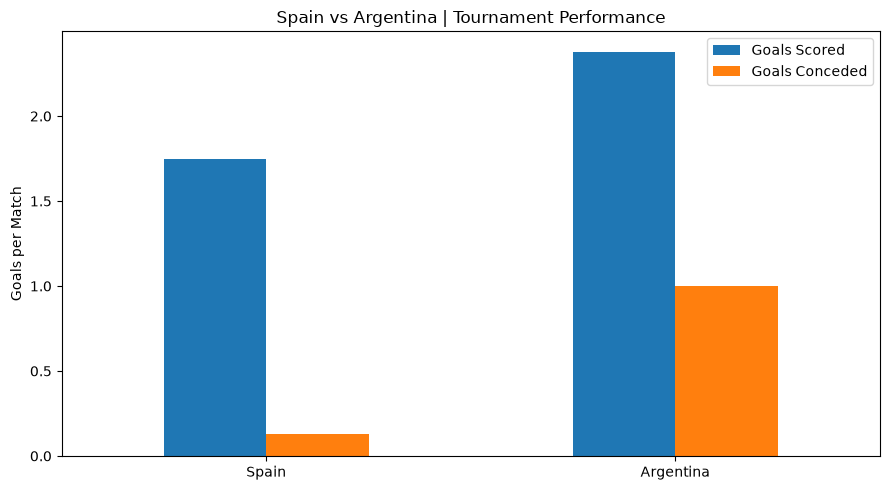

Chart and table saved successfully!


In [4]:
import matplotlib.pyplot as plt

# Prepare team performance data
query = """
WITH team_results AS (
    SELECT
        home_team AS team,
        home_score AS goals_for,
        away_score AS goals_against
    FROM matches

    UNION ALL

    SELECT
        away_team AS team,
        away_score AS goals_for,
        home_score AS goals_against
    FROM matches
)

SELECT
    team,
    ROUND(AVG(goals_for), 2) AS goals_per_match,
    ROUND(AVG(goals_against), 2) AS conceded_per_match

FROM team_results
WHERE team IN ('Spain', 'Argentina')
GROUP BY team
ORDER BY team DESC;
"""

visual_df = pd.read_sql_query(query, conn)

# Create comparison chart
ax = visual_df.set_index("team")[
    ["goals_per_match", "conceded_per_match"]
].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Spain vs Argentina | Tournament Performance")
ax.set_xlabel("")
ax.set_ylabel("Goals per Match")
ax.legend(["Goals Scored", "Goals Conceded"])

# Save the SQL results as a CSV table
visual_df.to_csv(
    tables_dir / "team_performance.csv",
    index=False
)

# Format and save the chart as a high-resolution PNG
plt.tight_layout()

ax.figure.savefig(
    charts_dir / "team_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart and table saved successfully!")

### 6.2 | Comparing Individual Goal Contributions

I compare the leading goalscorers from Spain and Argentina to understand how individual players contributed to their teams' attacking performance.

The visualization uses goal-event data extracted through SQL and focuses on the five highest-scoring players across both teams.

,team,player,goals_scored
0,Argentina,Lionel MESSI,8
1,Spain,Mikel OYARZABAL,5
2,Argentina,Lautaro MARTINEZ,3
3,Argentina,Enzo FERNANDEZ,2
4,Spain,Mikel MERINO,2


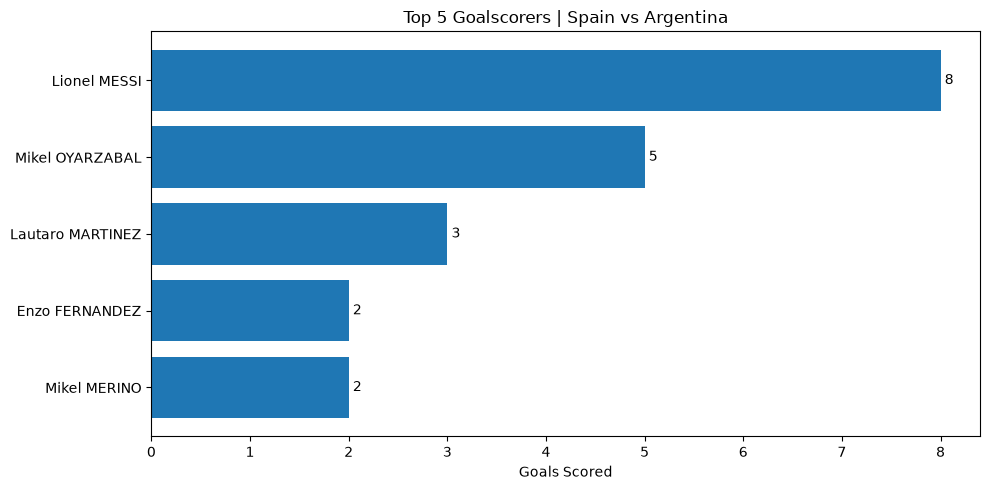

Top goalscorers chart and table saved successfully!


In [5]:
# Retrieve the leading goalscorers from Spain and Argentina
query = """
SELECT
    ma.team,
    ma.player_name AS player,
    COUNT(pe.event_id) AS goals_scored

FROM player_events pe

JOIN match_appearances ma
    ON pe.appearance_id = ma.appearance_id

WHERE pe.event_type = 'goal'
    AND ma.team IN ('Spain', 'Argentina')

GROUP BY
    ma.team,
    ma.player_id,
    ma.player_name

ORDER BY goals_scored DESC, player
LIMIT 5;
"""

top_scorers_df = pd.read_sql_query(query, conn)

display(top_scorers_df)

# Visualize the top five goalscorers
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    top_scorers_df["player"],
    top_scorers_df["goals_scored"]
)

ax.invert_yaxis()
ax.set_title("Top 5 Goalscorers | Spain vs Argentina")
ax.set_xlabel("Goals Scored")
ax.set_ylabel("")

ax.bar_label(bars, padding=3)

# Save the top goalscorers SQL results
top_scorers_df.to_csv(
    tables_dir / "top_5_goalscorers.csv",
    index=False
)

# Save the visualization as a high-resolution PNG
plt.tight_layout()

fig.savefig(
    charts_dir / "top_5_goalscorers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Top goalscorers chart and table saved successfully!")

### 6.3 | Goal Dependency: Leading Scorers

I measure the share of each team's total goals contributed by its leading scorer.

Using SQL, I combine individual goal-event counts with match-level team totals. The comparison helps assess scoring concentration and the extent to which each team relied on its top goalscorer.

,team,player,goals_scored,total_goals,contribution_pct
0,Argentina,Lionel MESSI,8,19,42.1
1,Spain,Mikel OYARZABAL,5,14,35.7


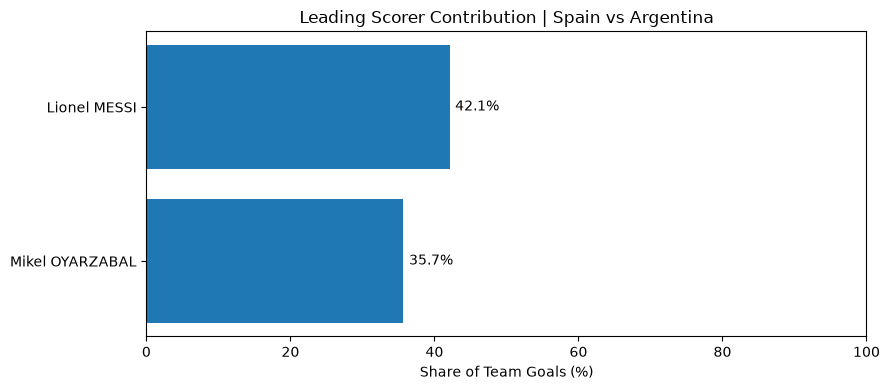

Goal dependency chart and table saved successfully!


In [6]:
# Compare leading scorer contributions using SQL
query = """
WITH player_goals AS (
    SELECT
        ma.team,
        ma.player_name AS player,
        COUNT(pe.event_id) AS goals_scored
    FROM player_events pe
    JOIN match_appearances ma
        ON pe.appearance_id = ma.appearance_id
    WHERE pe.event_type = 'goal'
      AND ma.team IN ('Spain', 'Argentina')
    GROUP BY ma.team, ma.player_id, ma.player_name
),

team_goals AS (
    SELECT team, SUM(goals) AS total_goals
    FROM (
        SELECT home_team AS team, home_score AS goals
        FROM matches

        UNION ALL

        SELECT away_team AS team, away_score AS goals
        FROM matches
    )
    WHERE team IN ('Spain', 'Argentina')
    GROUP BY team
),

ranked_players AS (
    SELECT
        pg.team,
        pg.player,
        pg.goals_scored,
        tg.total_goals,
        ROUND(
            100.0 * pg.goals_scored / tg.total_goals, 1
        ) AS contribution_pct,
        ROW_NUMBER() OVER (
            PARTITION BY pg.team
            ORDER BY pg.goals_scored DESC
        ) AS player_rank
    FROM player_goals pg
    JOIN team_goals tg
        ON pg.team = tg.team
)

SELECT
    team,
    player,
    goals_scored,
    total_goals,
    contribution_pct
FROM ranked_players
WHERE player_rank = 1
ORDER BY contribution_pct DESC;
"""

dependency_df = pd.read_sql_query(query, conn)

display(dependency_df)

# Visualize goal dependency
fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    dependency_df["player"],
    dependency_df["contribution_pct"]
)

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of Team Goals (%)")
ax.set_title("Leading Scorer Contribution | Spain vs Argentina")

ax.bar_label(bars, fmt="%.1f%%", padding=4)

# Save goal dependency SQL results
dependency_df.to_csv(
    tables_dir / "goal_dependency.csv",
    index=False
)

# Save the chart as a high-resolution PNG
plt.tight_layout()

fig.savefig(
    charts_dir / "goal_dependency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Goal dependency chart and table saved successfully!")

### 6.4 | Defensive Performance and Clean Sheets

I compare Spain's and Argentina's defensive consistency by calculating the number of clean sheets, total goals conceded, and clean-sheet percentage.

This analysis uses SQL conditional aggregation to measure how frequently each team prevented its opponents from scoring.

,team,matches_played,clean_sheets,total_conceded,clean_sheet_pct
0,Spain,8,7,1,87.5
1,Argentina,8,2,8,25.0


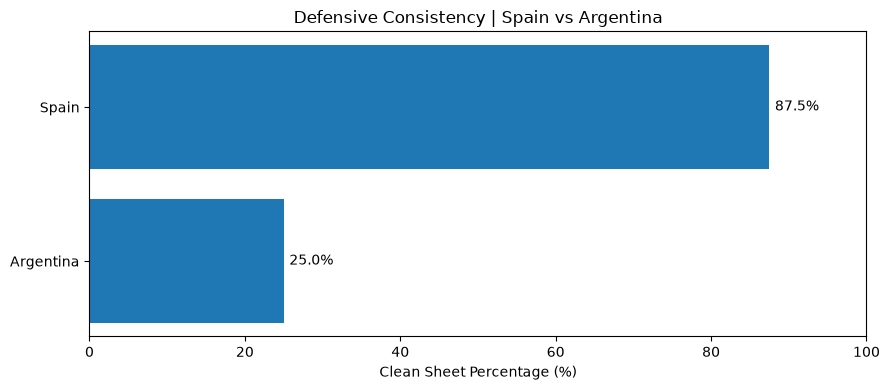

Defensive consistency chart and table saved successfully!


In [7]:
# Analyze defensive consistency using SQL
query = """
WITH team_matches AS (
    SELECT
        home_team AS team,
        away_score AS goals_conceded
    FROM matches

    UNION ALL

    SELECT
        away_team AS team,
        home_score AS goals_conceded
    FROM matches
)

SELECT
    team,
    COUNT(*) AS matches_played,
    SUM(CASE WHEN goals_conceded = 0 THEN 1 ELSE 0 END)
        AS clean_sheets,
    SUM(goals_conceded) AS total_conceded,
    ROUND(
        100.0 * SUM(
            CASE WHEN goals_conceded = 0 THEN 1 ELSE 0 END
        ) / COUNT(*), 1
    ) AS clean_sheet_pct

FROM team_matches
WHERE team IN ('Spain', 'Argentina')
GROUP BY team
ORDER BY clean_sheet_pct DESC;
"""

defense_df = pd.read_sql_query(query, conn)

display(defense_df)

# Visualize clean-sheet percentage
fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    defense_df["team"],
    defense_df["clean_sheet_pct"]
)

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Clean Sheet Percentage (%)")
ax.set_title("Defensive Consistency | Spain vs Argentina")

ax.bar_label(bars, fmt="%.1f%%", padding=4)

# Save defensive performance SQL results
defense_df.to_csv(
    tables_dir / "defensive_consistency.csv",
    index=False
)

# Save the chart as a high-resolution PNG
plt.tight_layout()

fig.savefig(
    charts_dir / "defensive_consistency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Defensive consistency chart and table saved successfully!")